# In-class work 13. Predicting a control object, and artificial immune systems

Industrial AI, KBTU. Goes with Lecture 13, "Predicting the behavior of control
objects", and with Lecture 12, "Intellectual complex objects control. Artificial immune systems
approach".

**Part 1. Predicting the object.** A storage tank is fed by a pump and drained through a valve at
the bottom. From a historian log we fit a linear model of the tank by least squares and ask three
questions. How far ahead can it predict? How many past values should it use? Can the mismatch
between the model and the tank tell us that something broke?

**Part 2. Artificial immune systems.** The immune system learns what the body's own cells look
like and attacks everything else. Negative selection copies this idea for fault detection: it
learns from normal data only. We build it step by step on two sensors, see where it fails, and
finish with clonal selection, the second algorithm of the family, used here for optimisation.

Everything is simulated in the notebook, so there are no data files. Run top to bottom with
`Shift+Enter`, about a minute.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

from math import gamma, log, pi
from matplotlib.patches import Circle

BLUE, ORANGE, RED, GREEN, PURPLE, GREY = (
    "#2a6f8e", "#e07b39", "#c0392b", "#4a8f5a", "#9b3f9b", "#9aa0a6")

mpl.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#cccccc",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e6e6",
    "grid.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelsize": 10,
    "font.size": 10,
    "font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"],
    "legend.frameon": False,
    "lines.linewidth": 1.6,
})

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

print(" | ".join(f"{m} {sys.modules[m].__version__}" for m in
                 ("numpy", "pandas", "matplotlib", "scipy", "sklearn", "torch") if m in sys.modules))

numpy 2.5.5 | pandas 3.1.1 | matplotlib 3.11.2


---

# Part 1. Predicting the behaviour of a control object

## 1.1 The tank and its historian

| quantity | value |
|---|---|
| cross-section $A$ | 1.5 m² |
| inflow | $q_{in} = k\,u$, $k$ = 0.0005 m³/s per % of pump command $u$ |
| inlet pipe | the water reaches the tank 20 s after the pump moves |
| outflow through the bottom valve | $q_{out} = c\sqrt{h}$, $c$ = 0.025 |
| disturbance | a slowly wandering extra inflow, about 1.5 % of the flow |
| level transmitter | noise with σ = 1 cm |
| historian | one sample every 10 s, 4000 samples (11 hours) |

The mass balance is

$$A\,\frac{dh}{dt} = k\,u(t - 20\ \text{s}) - c\sqrt{h} + q_{d}(t).$$

The square root makes the tank **nonlinear**. In steady state $dh/dt = 0$, so $h = (k u / c)^2$:
at $u$ = 50 % the level is 1 m. The local gain is the slope of that parabola,
$dh/du = 2k^2u/c^2$, and it grows with $u$. One more percent of pump raises the level by 4 cm at
50 % and by 4.8 cm at 60 %. The operators moved the pump between 38 and 62 % during the shift.

Linearising the balance around a level $h_0$ gives the time constant of the tank,
$\tau = 2A\sqrt{h_0}/c$: 120 s at 1 m. Keep the number; the model will find it by itself.

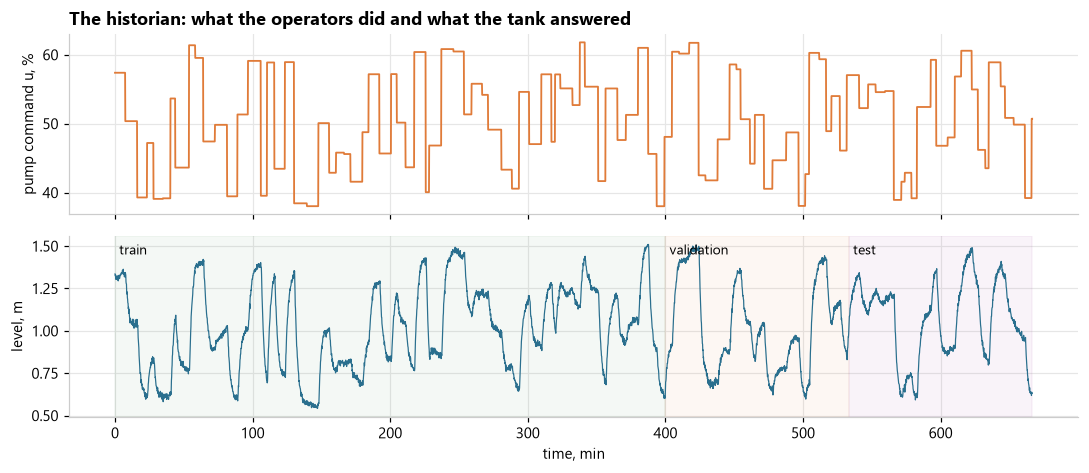

level from 0.54 to 1.51 m | train 2400, validation 800, test 800 samples


In [2]:
DT = 10.0              # sampling time of the historian, s
AREA = 1.5             # cross-section of the tank, m2
K_PUMP = 0.0005        # inflow per % of pump command, m3/s
C_OUT = 0.025          # outflow coefficient of the bottom valve, m2.5/s
PIPE = 2               # transport delay of the inlet pipe, samples
N = 4000
TRAIN, VAL, TEST = slice(0, 2400), slice(2400, 3200), slice(3200, 4000)


def pump_schedule(n, seed=5):
    # the operators' moves: hold a pump command for 15-60 samples, then pick a new one
    rng = np.random.default_rng(seed)
    u = np.empty(n)
    t = 0
    while t < n:
        hold = rng.integers(15, 61)
        u[t:t + hold] = rng.uniform(38, 62)
        t += hold
    return u


def simulate_tank(u, seed=13, t_fault=None, bias=0.0, leak=0.0):
    # Euler with 1 s sub-steps; returns the measured level y and the true level h,
    # both in m. From sample t_fault on, the transmitter reads `bias` m high and `leak`
    # m3/s leaves the tank.
    rng = np.random.default_rng(seed)
    n = len(u)
    h_true, y = np.empty(n), np.empty(n)
    h = (K_PUMP * u[0] / C_OUT) ** 2            # start in steady state
    qd = 0.0                                     # the wandering extra inflow
    for t in range(n):
        faulty = t_fault is not None and t >= t_fault
        offset = bias if faulty else 0.0
        extra_out = leak if faulty else 0.0

        # the historian sample, then the inflow over the next 10 s
        h_true[t] = h
        y[t] = h + 0.01 * rng.normal() + offset
        qd = 0.9 * qd + 0.00015 * rng.normal()
        q_in = K_PUMP * u[max(t - PIPE, 0)] + qd
        for _ in range(int(DT)):
            q_out = C_OUT * np.sqrt(max(h, 0.0)) + extra_out
            h = max(h + (q_in - q_out) / AREA, 0.0)
    return y, h_true


u = pump_schedule(N)
y, h_true = simulate_tank(u)
minutes = np.arange(N) * DT / 60

fig, axes = plt.subplots(2, 1, figsize=(10, 4.4), sharex=True)
axes[0].plot(minutes, u, color=ORANGE, lw=1.2)
axes[0].set(ylabel="pump command u, %",
            title="The historian: what the operators did and what the tank answered")
axes[1].plot(minutes, y, color=BLUE, lw=0.8, label="measured level y")
parts = [(TRAIN, "train", GREEN), (VAL, "validation", ORANGE), (TEST, "test", PURPLE)]
for sl, name, col in parts:
    axes[1].axvspan(minutes[sl.start], minutes[sl.stop - 1], alpha=0.06, color=col)
    axes[1].text(minutes[sl.start] + 3, y.max(), name, va="top", fontsize=9)
axes[1].set(xlabel="time, min", ylabel="level, m")
fig.tight_layout()
plt.show()
print(f"level from {y.min():.2f} to {y.max():.2f} m | train {TRAIN.stop - TRAIN.start}, "
      f"validation {VAL.stop - VAL.start}, test {TEST.stop - TEST.start} samples")

## 1.2 An ARX model by least squares

ARX means AutoRegressive with eXogenous input: the next level is a weighted sum of past levels and
past pump commands. The method in one table:

| step | formula |
|---|---|
| model ARX($n_a$, $n_b$, $n_k$) | $y_t = a_1 y_{t-1} + \dots + a_{n_a} y_{t-n_a} + b_1 u_{t-n_k} + \dots + b_{n_b} u_{t-n_k-n_b+1} + c + e_t$ |
| regressor and parameters | $\boldsymbol{\varphi}_t = (y_{t-1}, \dots, y_{t-n_a},\ u_{t-n_k}, \dots, u_{t-n_k-n_b+1},\ 1)^\top$, $\boldsymbol{\theta} = (a_1, \dots, b_1, \dots, c)^\top$ |
| all rows at once | $\mathbf{y} = \boldsymbol{\Phi}\boldsymbol{\theta} + \mathbf{e}$, row $t$ of $\boldsymbol{\Phi}$ is $\boldsymbol{\varphi}_t^\top$ |
| loss | $J(\boldsymbol{\theta}) = (\mathbf{y} - \boldsymbol{\Phi}\boldsymbol{\theta})^\top (\mathbf{y} - \boldsymbol{\Phi}\boldsymbol{\theta})$ |
| set the gradient to zero | $-2\boldsymbol{\Phi}^\top (\mathbf{y} - \boldsymbol{\Phi}\boldsymbol{\theta}) = \mathbf{0}$ |
| normal equations | $\boldsymbol{\Phi}^\top\boldsymbol{\Phi}\ \hat{\boldsymbol{\theta}} = \boldsymbol{\Phi}^\top \mathbf{y}$ |
| steady-state gain | $K = (b_1 + \dots + b_{n_b}) / (1 - a_1 - \dots - a_{n_a})$ |

- $n_a$ is how many past levels, $n_b$ how many past inputs, $n_k$ the delay in samples.
- $c$ absorbs the operating point, so we do not have to subtract means.
- The model is linear in $\boldsymbol{\theta}$, so least squares has one answer, found by solving
  a small linear system. No iterations.

The geometry behind the normal equations: $\boldsymbol{\Phi}\hat{\boldsymbol{\theta}}$ is the
orthogonal projection of $\mathbf{y}$ onto the space spanned by the columns of
$\boldsymbol{\Phi}$. The equations say that the residual $\mathbf{y} - \boldsymbol{\Phi}\hat{
\boldsymbol{\theta}}$ is orthogonal to every column. On the training data the residual is
uncorrelated with every past level and input the model was given: whatever it still contains,
the model had no linear way to predict.

The gain formula comes from the steady state. If $u$ and $y$ stay constant, the model reads
$y = (\sum a_i)\, y + (\sum b_j)\, u + c$, and solving for the slope $dy/du$ gives $K$.

The model is linear, but the roots of $z^{n_a} - a_1 z^{n_a - 1} - \dots - a_{n_a}$ (its poles)
still carry physics. A pole $z$ means that a disturbance decays as $z^t$ per sample, which is a
time constant of $-\Delta t / \ln z$.

We start with ARX(2, 2, 3). The pipe delays the water by two samples, and the level shows it one
sample later, so $n_k$ = 3. Two past levels and two past inputs are a first guess.

In [3]:
def arx_start(sl, na, nb, nk):
    # first time index of sl with every regressor available
    return max(sl.start, na, nk + nb - 1)


def arx_rows(y, u, na, nb, nk, idx):
    # regressor matrix Phi (len(idx) x (na + nb + 1)) and the target y[idx]
    past_y = [y[idx - i] for i in range(1, na + 1)]
    past_u = [u[idx - nk - j] for j in range(nb)]
    Phi = np.column_stack(past_y + past_u + [np.ones(len(idx))])
    return Phi, y[idx]


def fit_arx(y, u, na, nb, nk, sl):
    idx = np.arange(arx_start(sl, na, nb, nk), sl.stop)
    Phi, target = arx_rows(y, u, na, nb, nk, idx)
    return np.linalg.solve(Phi.T @ Phi, Phi.T @ target)         # the normal equations


def one_step(theta, y, u, na, nb, nk, sl):
    # one-step-ahead prediction on sl from measured past values;
    # returns (indices, prediction, target)
    idx = np.arange(arx_start(sl, na, nb, nk), sl.stop)
    Phi, target = arx_rows(y, u, na, nb, nk, idx)
    return idx, Phi @ theta, target


def rmse(e):
    return float(np.sqrt(np.mean(np.square(e))))


ORDER = (2, 2, 3)
na0, nb0, _ = ORDER
theta = fit_arx(y, u, *ORDER, TRAIN)

# the same fit by another solver, on the same rows
idx_train = np.arange(arx_start(TRAIN, *ORDER), TRAIN.stop)
Phi, target = arx_rows(y, u, *ORDER, idx_train)
check = np.linalg.lstsq(Phi, target, rcond=None)[0]
a, b = theta[:na0], theta[na0:na0 + nb0]
print("theta =", np.round(theta, 5))
print(f"same as numpy lstsq: {np.allclose(theta, check)}   "
      f"condition number of Phi'Phi: {np.linalg.cond(Phi.T @ Phi):.2e}")

for name, sl in [("train", TRAIN), ("validation", VAL)]:
    _, pred, tg = one_step(theta, y, u, *ORDER, sl)
    print(f"one-step RMSE on {name:10s}: {100 * rmse(tg - pred):.2f} cm")

poles = np.roots(np.r_[1, -a])
slow = poles[np.argmax(np.abs(poles))].real
tau_slow = -DT / np.log(slow)
print(f"\npoles of the model: {np.round(poles.real, 4)}; "
      f"the slow one gives a time constant of {tau_slow:.0f} s")
K = b.sum() / (1 - a.sum())
print(f"steady-state gain of the model: {100 * K:.2f} cm per % of pump")
for u0 in (40, 50, 60):
    gain_cm = 100 * 2 * (K_PUMP / C_OUT) ** 2 * u0          # dh/du = 2 k^2 u / c^2, in cm
    print(f"  true local gain of the tank at u = {u0} %: {gain_cm:.2f} cm per %")

theta = [ 0.46626  0.41694  0.00289  0.00178 -0.11502]
same as numpy lstsq: True   condition number of Phi'Phi: 5.06e+07
one-step RMSE on train     : 1.21 cm
one-step RMSE on validation: 1.24 cm

poles of the model: [ 0.9196 -0.4534]; the slow one gives a time constant of 119 s
steady-state gain of the model: 4.00 cm per % of pump
  true local gain of the tank at u = 40 %: 3.20 cm per %
  true local gain of the tank at u = 50 %: 4.00 cm per %
  true local gain of the tank at u = 60 %: 4.80 cm per %


The one-step error is about the size of the transmitter noise, 1 cm, plus a little from the
disturbance. That looks excellent and says very little: to predict 10 s ahead, "the level stays
where it is" is already a good guess.

The other two lines say more. The slow pole, 0.92 per sample, is a time constant of 119 s,
against the 120 s that $2A\sqrt{h_0}/c$ gives at 1 m. The gain is 4.00 cm per %, exactly the tank's gain at
50 %. The model has found the tank at the middle of its range. It has one gain for the whole
range, though, while the tank's gain grows with the level, so far from the middle the model will
be wrong in the slow part of the answer.

The condition number of $\boldsymbol{\Phi}^\top\boldsymbol{\Phi}$ is large because the columns
are nearly parallel: $y_{t-1}$ and $y_{t-2}$ differ by millimetres, and both sit near the column
of ones. `lstsq` works on $\boldsymbol{\Phi}$ itself and loses fewer digits, but here both
solvers agree.

## 1.3 One step ahead against free run

The same $\hat{\boldsymbol{\theta}}$ can be used in two ways.

| use | what goes into $\boldsymbol{\varphi}_t$ | what it answers |
|---|---|---|
| one-step prediction $\hat y_t^{(1)}$ | measured $y_{t-1}, y_{t-2}, \dots$ | where will the level be in 10 s? |
| $k$-step prediction $\hat y_{t+k}^{(k)}$ | measured $y$ up to $t$, then the model's own predictions | where in $10k$ seconds, if the pump follows the plan? |
| free run (simulation) $\hat y_t^{sim}$ | only the model's own past outputs, after the first $n_a$ samples | how does the tank answer this input sequence? A "digital twin" |

Least squares minimised $J$, the sum of squared **one-step** errors. Nothing in the fit looked at
the simulation error. In a free run the prediction is fed back as the input of the next step.
Subtract the free-run equation from the true one and the error $\varepsilon_t = y_t - \hat y_t^{sim}$
obeys

$$\varepsilon_t = a_1 \varepsilon_{t-1} + \dots + a_{n_a} \varepsilon_{t-n_a} + (\text{what the model gets wrong at step } t).$$

The error is filtered through the model's own dynamics. With a slow pole of 0.92 an error made
now still has $0.92^{12} \approx 0.37$ of its size two minutes later, and new errors keep
arriving. So the free-run error grows with the horizon and levels off after a few time constants.

validation RMSE   one step 1.24 cm   free run 2.04 cm


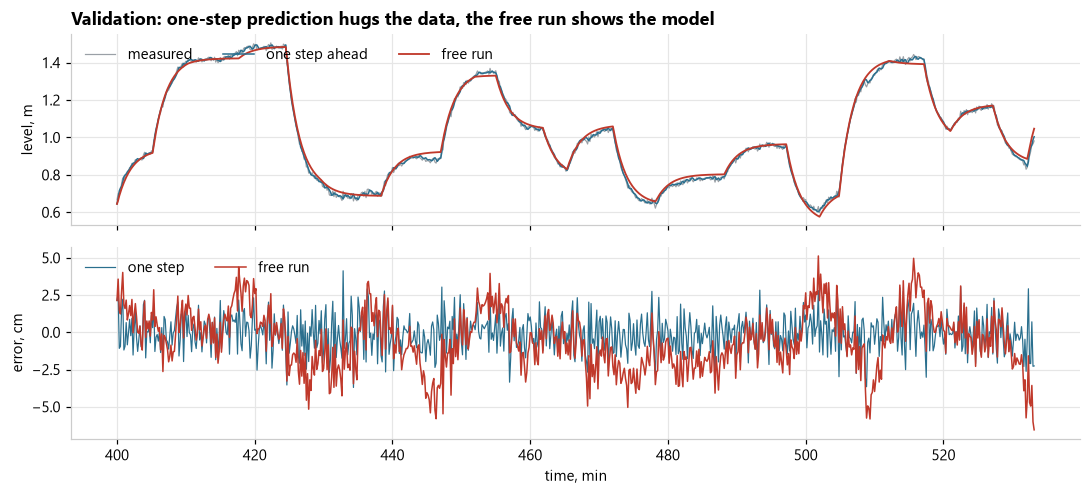

In [4]:
def free_run(theta, y, u, na, nb, nk, t0, t1):
    # simulation on [t0, t1): measured y only before t0, as initial conditions
    yh = y.astype(float).copy()
    for t in range(t0, t1):
        past_y = [yh[t - i] for i in range(1, na + 1)]   # from t0 on: the model's own
        past_u = [u[t - nk - j] for j in range(nb)]
        yh[t] = np.dot(past_y + past_u + [1.0], theta)
    return yh[t0:t1]


idx, pred1, target = one_step(theta, y, u, *ORDER, VAL)
sim = free_run(theta, y, u, *ORDER, VAL.start, VAL.stop)
print(f"validation RMSE   one step {100 * rmse(target - pred1):.2f} cm   "
      f"free run {100 * rmse(y[VAL] - sim):.2f} cm")

fig, axes = plt.subplots(2, 1, figsize=(10, 4.6), sharex=True)
t_min = minutes[VAL]
axes[0].plot(t_min, y[VAL], color=GREY, lw=0.8, label="measured")
axes[0].plot(minutes[idx], pred1, color=BLUE, lw=1, label="one step ahead")
axes[0].plot(t_min, sim, color=RED, lw=1.2, label="free run")
title = "Validation: one-step prediction hugs the data, the free run shows the model"
axes[0].set(ylabel="level, m", title=title)
axes[0].legend(ncol=3, loc="upper left")
axes[1].plot(minutes[idx], 100 * (target - pred1), color=BLUE, lw=0.8, label="one step")
axes[1].plot(t_min, 100 * (y[VAL] - sim), color=RED, lw=1, label="free run")
axes[1].set(xlabel="time, min", ylabel="error, cm")
axes[1].legend(ncol=2, loc="upper left")
fig.tight_layout()
plt.show()

Now the error as a function of the horizon. From every validation sample $t$ we predict
$k = 1, \dots, 90$ steps ahead (up to 15 minutes) and take the RMSE over all starting points.

k =   1 steps (  0.2 min): RMSE 1.23 cm
k =   3 steps (  0.5 min): RMSE 1.33 cm
k =   6 steps (  1.0 min): RMSE 1.50 cm
k =  12 steps (  2.0 min): RMSE 1.80 cm
k =  30 steps (  5.0 min): RMSE 2.04 cm
k =  60 steps ( 10.0 min): RMSE 2.04 cm
k =  90 steps ( 15.0 min): RMSE 2.11 cm


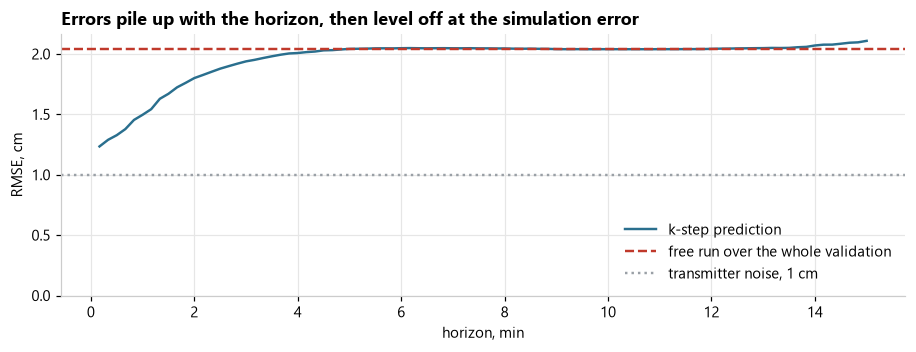

In [5]:
def k_step_errors(theta, y, u, na, nb, nk, sl, horizon):
    # RMSE of the 1..horizon step prediction, over every start in sl
    starts = np.arange(sl.start + 10, sl.stop - horizon)
    err = np.empty((len(starts), horizon))
    for i, s in enumerate(starts):
        err[i] = y[s:s + horizon] - free_run(theta, y, u, na, nb, nk, s, s + horizon)
    return np.sqrt(np.mean(err ** 2, axis=0))


H = 90
curve = k_step_errors(theta, y, u, *ORDER, VAL, H)
sim_level = rmse(y[VAL] - sim)
for k in (1, 3, 6, 12, 30, 60, 90):
    print(f"k = {k:3d} steps ({k * DT / 60:5.1f} min): RMSE {100 * curve[k - 1]:.2f} cm")

fig, ax = plt.subplots(figsize=(8.5, 3.3))
ax.plot(np.arange(1, H + 1) * DT / 60, 100 * curve, color=BLUE, label="k-step prediction")
ax.axhline(100 * sim_level, color=RED, ls="--",
           label="free run over the whole validation")
ax.axhline(1.0, color=GREY, ls=":", label="transmitter noise, 1 cm")
ax.set(xlabel="horizon, min", ylabel="RMSE, cm", ylim=(0, None),
       title="Errors pile up with the horizon, then level off at the simulation error")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

One step ahead the error is 1.23 cm, most of it transmitter noise. It grows fastest in the first
two minutes (1.80 cm at 12 steps) and stops at about 2.0 cm after five minutes, which is the
free-run error. Five minutes are 2.5 time constants of 120 s: by then the tank has forgotten the
level we started from, and only the input and the model are left.

The growth stops because the tank is stable: old errors die out as fast as new ones arrive. For an
integrating object, such as a tank emptied by a pump at a fixed rate, a pole sits at $z = 1$, old
errors never die out, and the error would keep growing.

The free-run error in the plot above stays on one side for minutes at a time. Part of it is the
wandering inflow, which no model of $u$ can know. Part is the single gain of the model: at 1.4 m
the tank answers the pump more strongly than the model's 4.0 cm per %.

There is a third, quieter reason. The past levels in $\boldsymbol{\varphi}_t$ are measured with
noise, and least squares with noisy regressors is biased (the errors-in-variables problem; Ljung,
1999). The bias barely matters for one step, where the noise is in the target too, but the free
run inherits it at every step.

## 1.4 Choosing the order on validation data

More parameters always lower the training error, so the order is chosen on data the fit has not
seen. We try $n_a$ = 1..4, $n_b$ = 1..3, $n_k$ = 1..3, 36 models, and score each one on the
validation part both ways.

In [6]:
scores = {}                     # (na, nb, nk) -> errors; a dict, so a re-run adds no rows
for na in range(1, 5):
    for nb in range(1, 4):
        for nk in range(1, 4):
            th = fit_arx(y, u, na, nb, nk, TRAIN)
            _, pr, tg = one_step(th, y, u, na, nb, nk, VAL)
            s = free_run(th, y, u, na, nb, nk, VAL.start, VAL.stop)
            scores[(na, nb, nk)] = dict(params=na + nb + 1,
                                        one_step_cm=100 * rmse(tg - pr),
                                        free_run_cm=100 * rmse(y[VAL] - s))
orders = pd.DataFrame(scores).T.rename_axis(["na", "nb", "nk"]).reset_index()
orders["params"] = orders["params"].astype(int)
print("Best five by one-step error:")
print(orders.sort_values("one_step_cm").head(5).round(3).to_string(index=False))
print("\nBest five by free-run error:")
print(orders.sort_values("free_run_cm").head(5).round(3).to_string(index=False))
print("\nFree-run RMSE in cm, nk = 3, rows na, columns nb:")
grid = orders[orders.nk == 3].pivot(index="na", columns="nb", values="free_run_cm")
print(grid.round(2).to_string())

# the smallest model within 2 % of the best free run
ok = orders[orders.free_run_cm <= 1.02 * orders.free_run_cm.min()]
smallest = ok.sort_values(["params", "free_run_cm"]).iloc[0]
BEST = tuple(int(v) for v in smallest[["na", "nb", "nk"]])
theta_best = fit_arx(y, u, *BEST, TRAIN)
sim_test = free_run(theta_best, y, u, *BEST, TEST.start, TEST.stop)
_, p_test, tg_test = one_step(theta_best, y, u, *BEST, TEST)
print(f"\nchosen ARX{BEST}: test one step {100 * rmse(tg_test - p_test):.2f} cm, "
      f"free run {100 * rmse(y[TEST] - sim_test):.2f} cm")

Best five by one-step error:
 na  nb  nk  params  one_step_cm  free_run_cm
  4   3   3       8        1.188        2.014
  3   3   3       7        1.202        2.024
  4   2   3       7        1.205        2.020
  4   3   2       8        1.207        2.011
  3   2   3       6        1.210        2.022

Best five by free-run error:
 na  nb  nk  params  one_step_cm  free_run_cm
  4   3   2       8        1.207        2.011
  3   3   2       7        1.212        2.012
  4   3   3       8        1.188        2.014
  4   2   3       7        1.205        2.020
  3   2   3       6        1.210        2.022

Free-run RMSE in cm, nk = 3, rows na, columns nb:
nb     1     2     3
na                  
1  2.110 2.150 2.150
2  2.050 2.040 2.040
3  2.060 2.020 2.020
4  2.060 2.020 2.010

chosen ARX(2, 1, 3): test one step 1.22 cm, free run 2.64 cm


- The **one-step error** picks the largest model, ARX(4, 3, 3), and the differences sit in the
  third digit: 1.19 against 1.21 cm.
- The **free-run error** is 2.11–2.15 cm with one past level, and 2.01–2.06 cm for every model
  with $n_a \ge 2$. Beyond two past levels the extra parameters fit the colour of the noise, and
  the simulation does not improve.
- We take the smallest model within 2 % of the best free run: ARX(2, 1, 3), four parameters. On
  the test part it gives 1.22 cm one step and 2.64 cm free run.

Choose the order by the job the model will do. For a 10-minute forecast or a digital twin, that
is the free-run error. No linear order removes the nonlinearity of the square root. For that the
structure has to change, for example one ARX model per range of level.

## 1.5 The residual as a fault signal

The residual is what the model did not expect: $r_t = y_t - \boldsymbol{\varphi}_t^\top
\hat{\boldsymbol{\theta}}$, one step ahead. On a healthy tank it is noise. A fault changes the
tank, and the model, fitted on the healthy tank, stops matching.

| step | what we do |
|---|---|
| residual | $r_t = y_t - \boldsymbol{\varphi}_t^\top\hat{\boldsymbol{\theta}}$, one step ahead |
| slow faults | moving mean over the last $W$ = 30 samples (5 min): $m_t = \frac{1}{W}\sum_{j=0}^{W-1} r_{t-j}$ |
| threshold | the 99.9 % quantile of $\lvert r\rvert$ and of $\lvert m\rvert$ on **normal** validation data |
| alarm | $\lvert r_t\rvert$ or $\lvert m_t\rvert$ above its threshold |

Why a moving mean? If $r_t$ is noise with spread $\sigma$, the mean of $W$ values scatters by
$\sigma/\sqrt{W}$, about $0.18\,\sigma$ for $W = 30$. A fault that adds a constant $\delta$ to every
residual adds the full $\delta$ to the mean. Averaging divides the noise by $\sqrt{W}$ and leaves
a constant shift alone, so small persistent shifts become visible. The price is delay: the mean
needs about $W$ samples to take in the whole shift.

No fault examples are needed to set the threshold. We test two faults on the test part, both
starting at sample 3500, with the same pump moves and the same noise as the healthy run:

- **sensor bias**: the transmitter starts to read 5 cm high;
- **leak**: an extra outflow of 0.0015 m³/s, 6 % of the normal flow.

thresholds from normal validation data: |r| > 3.95 cm, |m| > 0.52 cm
a constant bias of 5 cm shifts r by 5 x (1 - sum a) = 5 x 0.105 = 0.53 cm


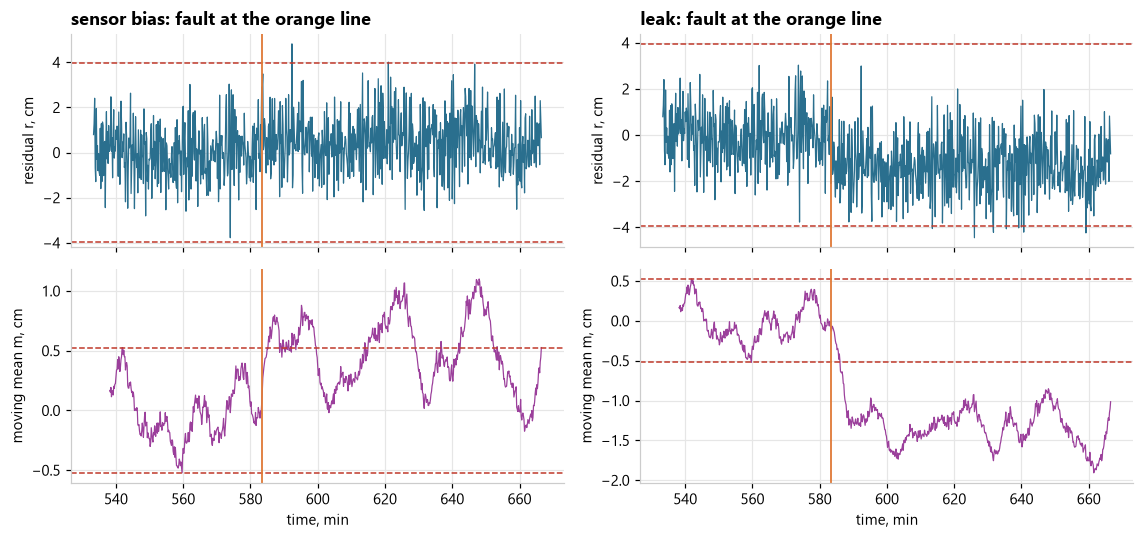

                        sensor bias    leak
false alarms before, r        0.000   0.000
false alarms before, m        0.010   0.010
flagged after, r              0.007   0.010
flagged after, m              0.533   0.943
mean r after, cm              0.512  -1.328
true level change, cm         0.000 -11.064


In [7]:
T_FAULT = 3500                           # fault onset, sample
W = 30                                   # moving-mean window, samples
SCEN = {                                 # name -> (measured level, true level)
    "healthy":     (y, h_true),
    "sensor bias": simulate_tank(u, t_fault=T_FAULT, bias=0.05),
    "leak":        simulate_tank(u, t_fault=T_FAULT, leak=0.0015),
}


def residuals(yy, sl):
    # one-step residual r of ARX BEST and its moving mean m over W samples
    # (NaN until W residuals exist)
    idx, pr, tg = one_step(theta_best, yy, u, *BEST, sl)
    r = tg - pr
    m = np.convolve(r, np.ones(W) / W)[:len(r)]
    m[:W - 1] = np.nan
    return idx, r, m


_, r_val, m_val = residuals(y, VAL)
THR_R = np.quantile(np.abs(r_val), 0.999)
THR_M = np.nanquantile(np.abs(m_val), 0.999)
sum_a = theta_best[:BEST[0]].sum()
print(f"thresholds from normal validation data: |r| > {100 * THR_R:.2f} cm, "
      f"|m| > {100 * THR_M:.2f} cm")
print(f"a constant bias of 5 cm shifts r by 5 x (1 - sum a) = 5 x {1 - sum_a:.3f} "
      f"= {5 * (1 - sum_a):.2f} cm")

table = {}
fig, axes = plt.subplots(2, 2, figsize=(10.5, 5), sharex=True)
for j, name in enumerate(["sensor bias", "leak"]):
    yy, hh = SCEN[name]
    idx, r, m = residuals(yy, TEST)
    before = idx < T_FAULT
    after = (idx >= T_FAULT) & (idx < T_FAULT + 300)     # 300 samples after the fault
    alarm_r = np.abs(r) > THR_R
    alarm_m = np.abs(np.nan_to_num(m)) > THR_M
    table[name] = {
        "false alarms before, r": alarm_r[before].mean(),
        "false alarms before, m": alarm_m[before].mean(),
        "flagged after, r": alarm_r[after].mean(),
        "flagged after, m": alarm_m[after].mean(),
        "mean r after, cm": 100 * r[after].mean(),
        "true level change, cm": 100 * (hh[T_FAULT + 299] - h_true[T_FAULT + 299]),
    }

    # top row: the residual, bottom row: its moving mean
    tm = minutes[idx]
    signals = [(r, THR_R, "residual r, cm", BLUE),
               (m, THR_M, "moving mean m, cm", PURPLE)]
    for row, (sig, thr, lab, colour) in enumerate(signals):
        ax = axes[row, j]
        ax.plot(tm, 100 * sig, color=colour, lw=0.8)
        ax.axhline(100 * thr, color=RED, ls="--", lw=1)
        ax.axhline(-100 * thr, color=RED, ls="--", lw=1)
        ax.axvline(minutes[T_FAULT], color=ORANGE, lw=1.2)
        ax.set(ylabel=lab)
        if row == 0:
            ax.set_title(f"{name}: fault at the orange line")
        else:
            ax.set_xlabel("time, min")
fig.tight_layout()
plt.show()
print(pd.DataFrame(table).round(3).to_string())

The raw residual misses both faults: after the fault it crosses its threshold on 0.7 % and 1.0 %
of the samples, as often as on healthy data. The moving mean catches the leak on 94 % of the 300
samples after it, with 1 % false alarms before it.

The leak is easy to explain. In each 10 s step it takes $0.0015 \cdot 10 / 1.5$ = 1 cm of level
out of the tank. The model starts every step from the measured level, so it does not accumulate
the leak; it misses roughly the same centimetre in every step. Over the 300 samples after the
fault the residual averages −1.33 cm, more than twice the threshold of the moving mean.

The sensor bias is harder, and the ARX equation says why. Add a constant $\beta$ to every measured
level. It enters $y_t$ and also every past level in $\boldsymbol{\varphi}_t$, so

$$r_t^{\text{bias}} = (y_t + \beta) - \sum_i a_i (y_{t-i} + \beta) - \dots - c
= r_t + \beta\,\Big(1 - \sum_i a_i\Big).$$

A stable, slow model has $\sum a_i$ close to 1, so most of the bias cancels. Here
$5\,(1 - \sum a_i)$ = 0.53 cm (the measured mean shift is 0.51 cm), right at the threshold of
0.52 cm. The moving mean flags 53 % of
the samples. On another day it could flag none. The same formula explains the leak too: a leak is
a change of the *tank*, not of the measurement, so nothing cancels.

The free run uses only the pump command and never looks at the transmitter after its start. Its
residual, measured minus simulated, should keep the full offset. Below, a free run started
200 samples before the faults.

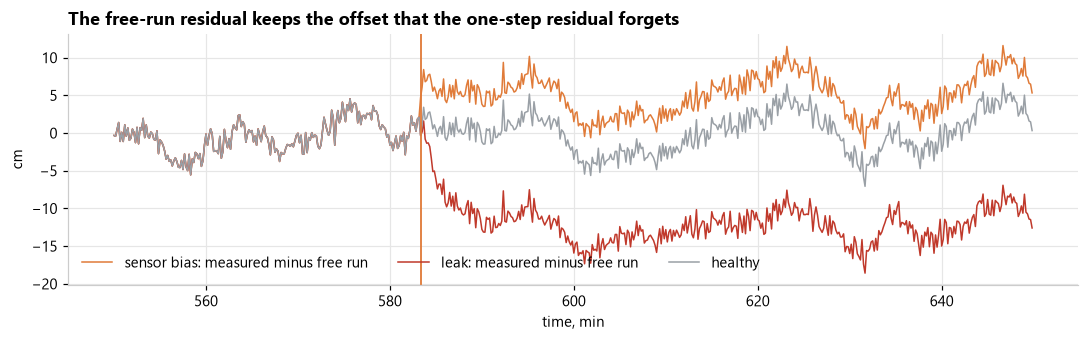

In [8]:
fig, ax = plt.subplots(figsize=(10, 3.2))
sl = slice(T_FAULT - 200, T_FAULT + 400)
for name, col in [("sensor bias", ORANGE), ("leak", RED), ("healthy", GREY)]:
    yy = SCEN[name][0]
    s = free_run(theta_best, yy, u, *BEST, sl.start, sl.stop)
    label = name if name == "healthy" else f"{name}: measured minus free run"
    ax.plot(minutes[sl], 100 * (yy[sl] - s), color=col, lw=1, label=label)
ax.axvline(minutes[T_FAULT], color=ORANGE, lw=1.2)
ax.set(xlabel="time, min", ylabel="cm",
       title="The free-run residual keeps the offset that the one-step residual forgets")
ax.legend(loc="lower left", ncol=3)
fig.tight_layout()
plt.show()

The bias stays in this residual as a 5 cm step, and the leak as a level that ends about 11 cm
below the model's. The price is width: the healthy free-run residual itself wanders by up to
7 cm, so its threshold has to be wide, and the free run has to be restarted from fresh
measurements now and then.

| residual | sees well | misses |
|---|---|---|
| one step, raw | sudden jumps larger than the noise | slow faults, small offsets |
| one step, moving mean | slow faults that add a steady change per step, like a leak | offsets in the measured signal itself |
| free run | offsets and drifts of the measurement | anything smaller than its own wander |

A plant monitor usually runs more than one of them.

---

# Part 2. Artificial immune systems

## 2.1 Self and non-self

| immune system | fault detection |
|---|---|
| the body's own cells, **self** | states seen in normal operation |
| everything foreign, **non-self** | faults, including ones never seen before |
| T-cells mature in the thymus; a cell that reacts to self is destroyed | negative selection: a random detector that matches normal data is deleted |
| a mature T-cell binds to a foreign cell | a detector that covers a new reading raises an alarm |
| B-cells that bind well are cloned and mutated | clonal selection: copy good solutions, mutate the copies, keep the better ones |

The object for this part is a fan motor with two readings scaled to $[0, 1]$: the motor current
$u_1$ and the winding temperature $u_2$. In normal operation the temperature follows the
current, roughly as $u_2 = 0.15 + 0.6\,u_1^2$ within ±0.05. That band is self. We have 120 normal
readings to train on, 400 more normal readings to test false alarms, and 400 abnormal readings to
test detection.

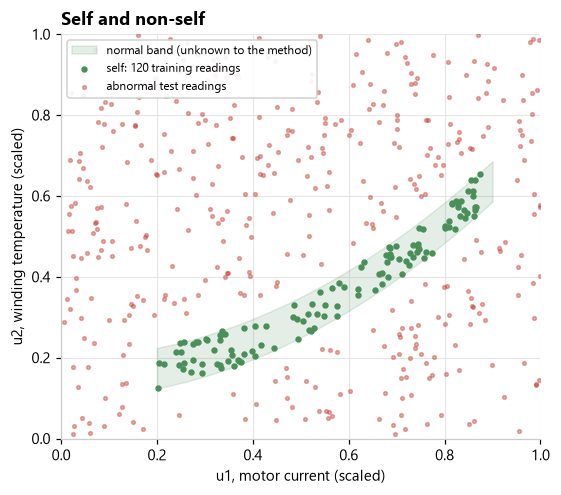

120 self, 400 normal test, 400 abnormal test (115 of them near the band)


In [9]:
def band(u1):
    return 0.15 + 0.6 * u1 ** 2


def sample_self(n, rng):
    u1 = rng.uniform(0.2, 0.9, n)
    u2 = band(u1) + rng.uniform(-0.05, 0.05, n)
    return np.column_stack([u1, u2])


def gap_from_band(x):
    # distance outside the normal band, 0 inside it (used for the ground truth only)
    gap = np.abs(x[:, 1] - band(np.clip(x[:, 0], 0.2, 0.9))) - 0.05
    side = np.maximum(0.2 - x[:, 0], x[:, 0] - 0.9)
    return np.maximum(np.maximum(gap, side), 0)


rng = np.random.default_rng(12)
SELF = sample_self(120, rng)
SELF_TEST = sample_self(400, rng)
probe = rng.random((20000, 2))
ANOM = probe[gap_from_band(probe) > 0.05][:400]          # clearly abnormal readings
NEAR = (gap_from_band(ANOM) < 0.15)                      # abnormal, but close to the band

G = np.linspace(0, 1, 151)
GRID = np.array(np.meshgrid(G, G)).reshape(2, -1).T
NONSELF_GRID = gap_from_band(GRID) > 0.05      # the area a detector set should cover

fig, ax = plt.subplots(figsize=(5.2, 4.6))
uu = np.linspace(0.2, 0.9, 100)
ax.fill_between(uu, band(uu) - 0.05, band(uu) + 0.05, color=GREEN, alpha=0.15,
                label="normal band (unknown to the method)")
ax.scatter(*SELF.T, s=10, color=GREEN, label="self: 120 training readings")
ax.scatter(*ANOM.T, s=6, color=RED, alpha=0.4, label="abnormal test readings")
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="u1, motor current (scaled)",
       ylabel="u2, winding temperature (scaled)", title="Self and non-self")
ax.legend(loc="upper left", fontsize=8, frameon=True, framealpha=0.9)
fig.tight_layout()
plt.show()
print(f"{len(SELF)} self, {len(SELF_TEST)} normal test, {len(ANOM)} abnormal test "
      f"({NEAR.sum()} of them near the band)")

## 2.2 Negative selection, step by step

| step | rule |
|---|---|
| 1. self set | normal readings $\mathbf{s}_1, \dots, \mathbf{s}_N$ |
| 2. candidate | a random point $\mathbf{c}$, uniform in $[0, 1]^2$ |
| 3. censoring | $\delta(\mathbf{c}) = \min_i \lVert \mathbf{c} - \mathbf{s}_i\rVert$. If $\delta(\mathbf{c}) \le r_s$ the candidate **is deleted**, otherwise it becomes a detector |
| 4. repeat | until there are $n_d$ detectors |
| 5. monitoring | a reading $\mathbf{x}$ is **abnormal** if $\lVert \mathbf{x} - \mathbf{c}_j\rVert \le r_d$ for at least one detector $\mathbf{c}_j$ |

$\lVert\cdot\rVert$ is the Euclidean distance, $r_s$ the self radius, $r_d$ the detector radius.
The method is trained on normal data only and needs no failure examples. It says "abnormal" or
"normal", and nothing about which fault. The first eight candidates with $r_s$ = 0.06:

In [10]:
def min_dist(a, b, chunk=4000):
    # distance from every row of a to the nearest row of b
    out = np.empty(len(a))
    b2 = (b ** 2).sum(1)
    for i in range(0, len(a), chunk):
        x = a[i:i + chunk]
        d2 = (x ** 2).sum(1)[:, None] + b2[None, :] - 2 * x @ b.T
        out[i:i + chunk] = np.sqrt(np.maximum(d2.min(1), 0))
    return out


def censor(self_pts, n_det, r_s, rng, batch=500, max_tries=2_000_000):
    # negative selection: random candidates, keep those farther than r_s from every self
    # point. Returns (detectors, number of candidates tried).
    d = self_pts.shape[1]
    kept, tried = [], 0
    while sum(len(k) for k in kept) < n_det and tried < max_tries:
        c = rng.random((batch, d))
        ok = np.flatnonzero(min_dist(c, self_pts) > r_s)     # survivors of this batch
        need = n_det - sum(len(k) for k in kept)
        if len(ok) >= need:
            # enough: count the candidates only up to the last one we keep
            kept.append(c[ok[:need]])
            tried += ok[need - 1] + 1
        else:
            kept.append(c[ok])
            tried += batch
    return np.vstack(kept), tried


def abnormal(x, detectors, r_d):
    return min_dist(x, detectors) <= r_d


R_S = 0.06
cand = np.random.default_rng(1).random((8, 2))
dist = min_dist(cand, SELF)
first_eight = pd.DataFrame({"u1": cand[:, 0], "u2": cand[:, 1], "nearest self": dist,
                            "verdict": np.where(dist <= R_S, "deleted", "detector")})
print(first_eight.round(3).to_string())

     u1    u2  nearest self   verdict
0 0.512 0.950         0.464  detector
1 0.144 0.949         0.706  detector
2 0.312 0.423         0.158  detector
3 0.828 0.409         0.074  detector
4 0.550 0.028         0.223  detector
5 0.754 0.538         0.018   deleted
6 0.330 0.788         0.463  detector
7 0.303 0.453         0.189  detector


Now the whole set: $n_d$ = 200 detectors, $r_s = r_d$ = 0.06.

How much should 200 detectors cover? Drop $n$ balls of area $V$ at random into a region of area
1. A given point escapes one ball with probability $1 - V$, and all of them with probability
$(1 - V)^n \approx e^{-nV}$. So the expected covered share is about $1 - e^{-nV}$. Here
$V = \pi r_d^2 = 0.0113$, and $1 - e^{-200 V}$ is printed below next to the measurement. The
formula ignores the edges of the square and the deleted zone around self, so it is a rough guide.

detectors      200
candidates     243
deleted        43
coverage       0.886
false_alarms   0.018
detected       0.877
detected_near  0.870
detected_far   0.881
random-ball estimate 1 - exp(-n pi r^2) = 0.896


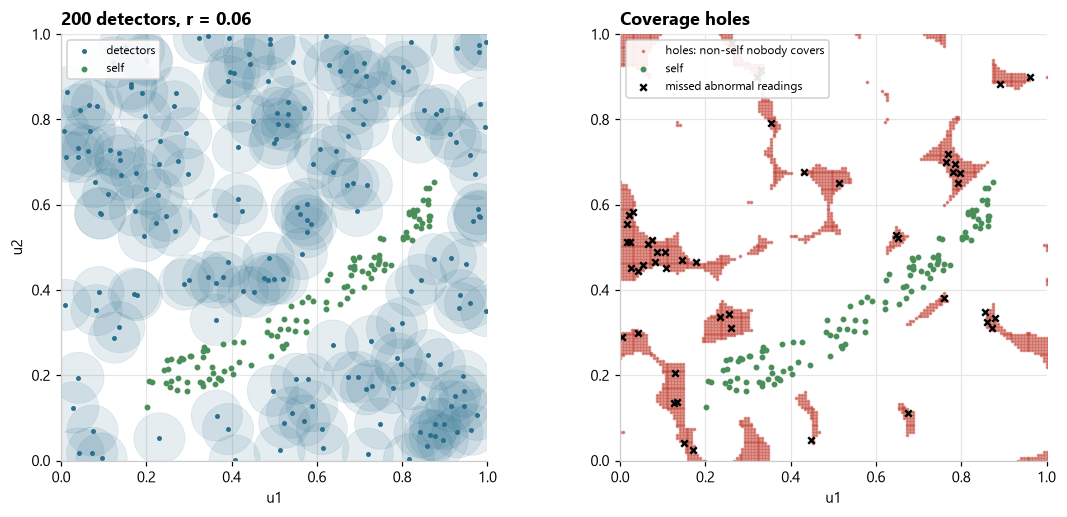

In [11]:
def ns_report(n_det, r_s, r_d, seed=0):
    det, tried = censor(SELF, n_det, r_s, np.random.default_rng(seed))
    covered = abnormal(GRID[NONSELF_GRID], det, r_d)
    false_alarm = abnormal(SELF_TEST, det, r_d)
    hit = abnormal(ANOM, det, r_d)
    return det, dict(detectors=len(det), candidates=tried, deleted=tried - len(det),
                     coverage=covered.mean(), false_alarms=false_alarm.mean(),
                     detected=hit.mean(), detected_near=hit[NEAR].mean(),
                     detected_far=hit[~NEAR].mean())


DET, rep = ns_report(200, R_S, R_S)
for k, v in rep.items():
    value = f"{v:.3f}" if isinstance(v, float) else f"{v}"
    print(f"{k:14s} {value}")
print(f"random-ball estimate 1 - exp(-n pi r^2) = {1 - np.exp(-200 * pi * R_S ** 2):.3f}")

hole = GRID[NONSELF_GRID][~abnormal(GRID[NONSELF_GRID], DET, R_S)]
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.8))
ax = axes[0]
for c in DET:
    ax.add_patch(Circle(c, R_S, fc=BLUE, ec=BLUE, alpha=0.12, lw=0.5))
ax.scatter(*DET.T, s=5, color=BLUE, label="detectors")
ax.scatter(*SELF.T, s=8, color=GREEN, label="self")
ax.set(xlim=(0, 1), ylim=(0, 1), aspect="equal", xlabel="u1", ylabel="u2",
       title=f"200 detectors, r = {R_S}")
ax.legend(loc="upper left", fontsize=8, frameon=True, framealpha=0.9)
ax = axes[1]
ax.scatter(*hole.T, s=2, color=RED, alpha=0.5, label="holes: non-self nobody covers")
ax.scatter(*SELF.T, s=8, color=GREEN, label="self")
missed = ANOM[~abnormal(ANOM, DET, R_S)]
ax.scatter(*missed.T, s=18, marker="x", color="black", label="missed abnormal readings")
ax.set(xlim=(0, 1), ylim=(0, 1), aspect="equal", xlabel="u1", title="Coverage holes")
ax.legend(loc="upper left", fontsize=8, frameon=True, framealpha=0.9)
fig.tight_layout()
plt.show()

Of 243 candidates, 43 were deleted, which leaves 200 detectors. They cover 88.6 % of the
non-self area, close to the 0.90 of the random-ball estimate. 87.7 % of the abnormal test
readings fall inside a detector, and so do 1.8 % of the normal test readings: these are false
alarms. They come from the gaps between the 120 training points. A detector can sit more than
0.06 from every training point and still cover a normal reading that lies between two of them.

The red patches on the right are holes. Detectors land where the random draws put them, so holes
appear near the band and far from it, and abnormal readings inside a hole are missed. Nothing in
the method guarantees that every abnormal state is covered; $e^{-nV}$ only shrinks as $n$ grows.

## 2.3 What $r_s$, $r_d$ and $n_d$ do

Three sweeps, each changes one setting from the base $n_d$ = 200, $r_s = r_d$ = 0.06.

In [12]:
settings = ([(n, 0.06, 0.06) for n in (50, 100, 200, 400, 800)]
            + [(200, 0.06, r) for r in (0.04, 0.08, 0.10)]
            + [(200, r, 0.06) for r in (0.03, 0.09, 0.12)])
rows = []
for n, rs, rd in settings:
    _, report = ns_report(n, rs, rd)
    rows.append(dict(n_d=n, r_s=rs, r_d=rd, **report))
sweep = pd.DataFrame(rows)
print(sweep.drop(columns=["detectors", "deleted"]).round(3).to_string(index=False))

 n_d   r_s   r_d  candidates  coverage  false_alarms  detected  detected_near  detected_far
  50 0.060 0.060          61     0.450         0.000     0.440          0.235         0.523
 100 0.060 0.060         120     0.683         0.000     0.660          0.565         0.698
 200 0.060 0.060         243     0.886         0.018     0.878          0.870         0.881
 400 0.060 0.060         487     0.980         0.038     0.968          0.957         0.972
 800 0.060 0.060         956     0.998         0.118     0.995          0.983         1.000
 200 0.060 0.040         243     0.646         0.000     0.628          0.661         0.614
 200 0.060 0.080         243     0.974         0.170     0.975          0.957         0.982
 200 0.060 0.100         243     0.994         0.552     0.995          0.991         0.996
 200 0.030 0.060         228     0.885         0.282     0.878          0.904         0.867
 200 0.090 0.060         267     0.867         0.000     0.872          0.791   

- **$n_d$.** From 50 to 800 detectors the coverage grows from 0.45 to 0.998, roughly along
  $1 - e^{-nV}$. The false alarms grow too, from 0 to 11.8 %: more detectors fill more of the gaps
  between the self samples.
- **$r_d$ above $r_s$.** A detector then reaches past the deleted zone onto normal data. With
  $r_d$ = 0.08 the false alarms are 17 %, with 0.10 they are 55 %. With $r_d$ = 0.04 a ring around
  self stays empty and the coverage falls to 0.65.
- **$r_s$.** A small $r_s$ = 0.03 lets detectors creep up to the band: near anomalies are caught
  more often (0.90), and false alarms jump to 28 %. A large $r_s$ = 0.12 keeps a wide ring with no
  detectors: no false alarms, and only 52 % of the near anomalies are caught.

$r_s$ says how far from the known normal data a reading starts to count as abnormal. Choosing it
means choosing between false alarms and missed early faults, the same trade as choosing an alarm
threshold.

## 2.4 Why negative selection struggles in high dimension

One detector covers a ball of radius $r$. Its volume in $d$ dimensions is

$$V_d(r) = \frac{\pi^{d/2}}{\Gamma(d/2 + 1)}\, r^d,$$

and the unit cube has volume 1. By the estimate of 2.2, $n$ random detectors cover about
$1 - e^{-n V_d}$ of the cube, so 90 % coverage needs about $n \approx \ln 10 / V_d(r)$ detectors.

$V_d$ falls fast for two reasons. The factor $r^d$ shrinks geometrically for $r < 1$. The constant
$\pi^{d/2}/\Gamma(d/2+1)$ also falls after $d = 5$, because almost all of the volume of a cube
lies in its corners, far from the centre of any ball inside it. At $r = 0.15$ the ball covers 7 %
of the square, and in ten dimensions a fraction of order $10^{-8}$.

Below, the formula next to a measurement. Self is a cluster of 200 normal points around the centre
of the cube; 1000 detectors with $r_s = r_d$ = 0.15; coverage estimated on 20 000 random points
farther than 0.15 from every self point.

 d ball_volume coverage_1000 detectors_for_90pct deleted_share
 2    7.07e-02         1.000                  33         0.351
 3    1.41e-02         1.000                 163         0.151
 4    2.50e-03         0.855                 922         0.055
 6    5.89e-05         0.041              39,117         0.003
 8    1.04e-06         0.001           2,213,591         0.000
10    1.47e-08         0.000         156,579,528         0.000


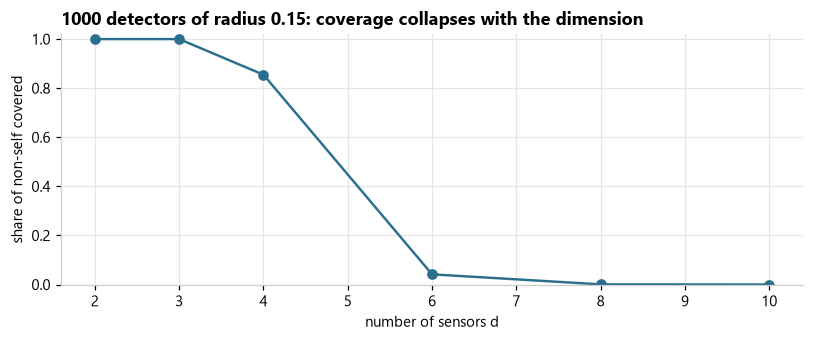

In [13]:
dims = {}
for d in (2, 3, 4, 6, 8, 10):
    rng = np.random.default_rng(d)
    self_d = np.clip(0.5 + 0.08 * rng.normal(size=(200, d)), 0, 1)
    det_d, tried = censor(self_d, 1000, 0.15, rng)
    pts = rng.random((20000, d))
    pts = pts[min_dist(pts, self_d) > 0.15]
    V = pi ** (d / 2) / gamma(d / 2 + 1) * 0.15 ** d          # volume of one detector
    dims[d] = dict(ball_volume=V, coverage_1000=abnormal(pts, det_d, 0.15).mean(),
                   detectors_for_90pct=log(10) / V, deleted_share=1 - 1000 / tried)
dims = pd.DataFrame(dims).T.rename_axis("d").reset_index()
dims["d"] = dims["d"].astype(int)
formats = {"ball_volume": "{:.2e}".format,
           "coverage_1000": "{:.3f}".format,
           "detectors_for_90pct": "{:,.0f}".format,
           "deleted_share": "{:.3f}".format}
print(dims.to_string(index=False, formatters=formats))

fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.plot(dims["d"], dims["coverage_1000"], "o-", color=BLUE)
ax.set(xlabel="number of sensors d", ylabel="share of non-self covered", ylim=(0, 1.02),
       title="1000 detectors of radius 0.15: coverage collapses with the dimension")
fig.tight_layout()
plt.show()

With two sensors, 33 random detectors of radius 0.15 would cover 90 % of the square. With ten
sensors one detector covers $1.5 \cdot 10^{-8}$ of the cube, and 90 % coverage would take about
$1.6 \cdot 10^{8}$ detectors. The measurement agrees: 1000 detectors cover 86 % of non-self at
$d$ = 4, 4 % at $d$ = 6 and nothing at $d$ = 10. Censoring also stops working as a filter: at
$d$ = 8 almost no candidate lands near the self cluster, so almost none is deleted.

What people do about it:

- reduce the dimension first, with PCA or a few engineered features;
- use detectors of different sizes, large far from self and small near it (the V-detector);
- run negative selection on the residuals of a model, like the one in Part 1, instead of on raw
  sensors.

**Why does the volume of a detector fall as $r^d$?**

<details><summary>Answer</summary>

Stretch the unit ball by $r$: every point $\mathbf{x}$ goes to $r\mathbf{x}$. Each of the $d$
coordinates is multiplied by $r$, so every small box inside the ball changes its volume by
$r \cdot r \cdots r = r^d$ (the Jacobian of $\mathbf{x} \mapsto r\mathbf{x}$ is $r^d$). Hence
$V_d(r) = V_d(1)\, r^d$ for any shape, the ball included; a cube of side $r$ is the simplest case.

For $r < 1$ each extra sensor multiplies the volume of one detector by $r$, on top of the change
of $V_d(1)$. With $r = 0.15$ that is a factor of 0.15 per sensor. This is the fall in the figure
above: 1000 detectors that cover 86 % of non-self at $d = 4$ cover nothing at $d = 10$. Doubling
the radius buys back a factor of $2^d$, 1024 at $d = 10$, but Part 2.3 showed the price: a larger
$r_d$ reaches onto self, and a larger $r_s$ misses the faults close to it. The cell below prints
the volumes.

</details>

In [14]:
# V_d(r) = V_d(1) r^d: the volume of one detector for two radii
for d in (2, 4, 10):
    unit_ball = pi ** (d / 2) / gamma(d / 2 + 1)
    small, large = unit_ball * 0.15 ** d, unit_ball * 0.30 ** d
    print(f"d = {d:2d}: V(1) = {unit_ball:.3f}, V(0.15) = {small:.2e}, "
          f"V(0.30) / V(0.15) = {large / small:.0f}")

d =  2: V(1) = 3.142, V(0.15) = 7.07e-02, V(0.30) / V(0.15) = 4
d =  4: V(1) = 4.935, V(0.15) = 2.50e-03, V(0.30) / V(0.15) = 16
d = 10: V(1) = 2.550, V(0.15) = 1.47e-08, V(0.30) / V(0.15) = 1024


## 2.5 Clonal selection (CLONALG)

The second immune algorithm copies how B-cells improve. Antibodies that bind well are cloned,
the clones mutate, and the better ones survive. Good antibodies mutate little, poor ones a lot.
De Castro and Von Zuben (2002) wrote it down as CLONALG and used it both for pattern recognition
and for optimisation. We use it to maximise a test function with many peaks:

$$f(x, y) = x \sin(4\pi x) - y \sin(4\pi y + \pi) + 1, \qquad x, y \in [-1, 2].$$

| step | rule (our simple version) |
|---|---|
| population | $N$ = 40 antibodies $\mathbf{p}_i$, random in the box; affinity = $f$ |
| selection | sort by affinity, take the best $n$ = 10 |
| cloning | antibody of rank $i$ gets $N_c = \mathrm{round}(\beta N / i)$ clones, $\beta$ = 1: 40, 20, 13, … |
| hypermutation | clone $= \mathbf{p}_i + \sigma\,\boldsymbol{\varepsilon}$, $\boldsymbol{\varepsilon} \sim \mathcal N(\mathbf{0}, \mathbf{I})$, $\sigma = 0.3\, e^{-\rho \bar f}$, $\bar f \in [0, 1]$ the affinity scaled within the population, $\rho$ = 3 |
| replacement | the best clone replaces its parent if it is better |
| receptor editing | the 4 worst antibodies are replaced by random ones |

The mutation rule splits the work. The best antibody has $\bar f = 1$ and mutates with
$\sigma = 0.3\,e^{-3} \approx 0.015$: a fine local search on its peak. The worst of the selected
ones mutate with $\sigma$ up to 0.3, a tenth of the box, and explore. Many clones for good
antibodies and large steps for poor ones is a budget split between exploitation and exploration.

One generation costs 121 evaluations of $f$. We run 25 generations, about 3000 evaluations, and
compare with random search on the same budget, ten seeds each.

grid maximum f* = 4.2536 | budget 3065 evaluations per run
CLONALG       best f: median 4.2538, worst 3.2569, within 0.01 of f*: 8 of 10 seeds
random search best f: median 4.0887, worst 3.8124, within 0.01 of f*: 1 of 10 seeds


seed 0: 18 of 40 antibodies sit on 13 different peaks (of 48 peaks with f > 1.5)


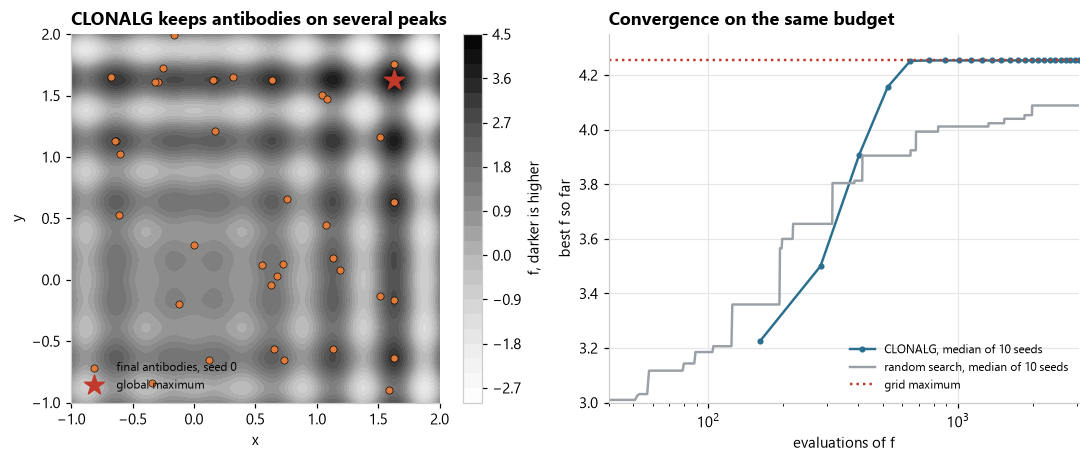

In [15]:
LO, HI = -1.0, 2.0


def peaks(p):
    x, y = p[:, 0], p[:, 1]
    return x * np.sin(4 * np.pi * x) - y * np.sin(4 * np.pi * y + np.pi) + 1


def clonalg(f, n_pop=40, n_sel=10, beta=1.0, rho=3.0, n_new=4, gens=50, seed=0):
    # returns (final population, its affinities, best affinity per generation,
    # evaluations used)
    rng = np.random.default_rng(seed)
    pop = rng.uniform(LO, HI, (n_pop, 2))
    fit = f(pop)
    evals = n_pop
    best = []
    for _ in range(gens):
        order = np.argsort(-fit)
        pop, fit = pop[order], fit[order]
        scaled = (fit - fit.min()) / (fit.max() - fit.min() + 1e-12)

        # clone and mutate the best n_sel; the best clone replaces its parent if better
        for i in range(n_sel):
            nc = int(round(beta * n_pop / (i + 1)))
            sigma = 0.3 * np.exp(-rho * scaled[i])        # good parent, small mutation
            clones = np.clip(pop[i] + sigma * rng.normal(size=(nc, 2)), LO, HI)
            fc = f(clones)
            evals += nc
            j = fc.argmax()
            if fc[j] > fit[i]:
                pop[i], fit[i] = clones[j], fc[j]

        # receptor editing: the n_new worst are replaced by random antibodies
        order = np.argsort(-fit)
        pop, fit = pop[order], fit[order]
        pop[-n_new:] = rng.uniform(LO, HI, (n_new, 2))
        fit[-n_new:] = f(pop[-n_new:])
        evals += n_new
        best.append(fit.max())
    return pop, fit, np.array(best), evals


g = np.linspace(LO, HI, 601)
GX, GY = np.meshgrid(g, g)
FZ = peaks(np.column_stack([GX.ravel(), GY.ravel()])).reshape(GX.shape)
f_star = FZ.max()

runs = [clonalg(peaks, gens=25, seed=s) for s in range(10)]
budget = runs[0][3]

# random search on the same budget: the best f so far after every evaluation
curves = []
for s in range(10):
    draws = np.random.default_rng(100 + s).uniform(LO, HI, (budget, 2))
    curves.append(np.maximum.accumulate(peaks(draws)))
rand_curves = np.array(curves)

clo_best = [r[2][-1] for r in runs]
rand_best = rand_curves[:, -1]
print(f"grid maximum f* = {f_star:.4f} | budget {budget} evaluations per run")
for name, finals in [("CLONALG      ", clo_best), ("random search", rand_best)]:
    near_top = sum(b > f_star - 0.01 for b in finals)
    print(f"{name} best f: median {np.median(finals):.4f}, worst {min(finals):.4f}, "
          f"within 0.01 of f*: {near_top} of 10 seeds")

# How many different peaks the final population sits on: the peaks are the local maxima
# of the grid above 1.5; an antibody within 0.1 of a peak sits on it.
from scipy.ndimage import maximum_filter
is_peak = (FZ == maximum_filter(FZ, size=25)) & (FZ > 1.5)
peak_xy = np.column_stack([GX[is_peak], GY[is_peak]])
pop, fit, best, _ = runs[0]
on_peak = min_dist(pop, peak_xy) < 0.1
nearest_peak = {int(np.argmin(((peak_xy - q) ** 2).sum(1))) for q in pop[on_peak]}
print(f"seed 0: {on_peak.sum()} of 40 antibodies sit on {len(nearest_peak)} "
      f"different peaks (of {len(peak_xy)} peaks with f > 1.5)")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.3))
ax = axes[0]
cs = ax.contourf(GX, GY, FZ, levels=25, cmap="Greys")
fig.colorbar(cs, ax=ax, label="f, darker is higher", fraction=0.04)
ax.grid(False)
ax.scatter(*pop.T, s=22, color=ORANGE, edgecolor="black", lw=0.4,
           label="final antibodies, seed 0")
top = peak_xy[np.argmax(peaks(peak_xy))]
ax.scatter(*top, marker="*", s=180, color=RED, label="global maximum")
ax.set(xlabel="x", ylabel="y", aspect="equal",
       title="CLONALG keeps antibodies on several peaks")
ax.legend(loc="lower left", fontsize=8)

ax = axes[1]
per_generation = (budget - 40) // len(best)                    # 121 evaluations
evals_at = 40 + per_generation * np.arange(1, len(best) + 1)
clonalg_median = np.median([r[2] for r in runs], axis=0)
ax.plot(evals_at, clonalg_median, "o-", ms=3, color=BLUE,
        label="CLONALG, median of 10 seeds")
ax.plot(np.arange(1, budget + 1), np.median(rand_curves, axis=0), color=GREY,
        label="random search, median of 10 seeds")
ax.axhline(f_star, color=RED, ls=":", label="grid maximum")
ax.set(xlabel="evaluations of f", ylabel="best f so far", xscale="log", xlim=(40, budget),
       ylim=(3, 4.35), title="Convergence on the same budget")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()

On 3065 evaluations CLONALG reaches the grid maximum on 8 of 10 seeds, random search on 1. Two
CLONALG seeds got stuck on a lower peak, and the worst of them ended at 3.26, below the worst
random search (3.81). The best antibody mutates with $\sigma \approx 0.015$, so it never jumps to
another peak. Only the four random newcomers per generation can find a better one.

At the end of seed 0, 18 of the 40 antibodies sit on 13 different peaks. The population keeps
several good answers at once. A plant can use the second-best setpoint when the best one is ruled
out for a reason the objective does not know.

For pattern recognition CLONALG keeps memory antibodies for each class and labels a new reading
by the nearest memory antibody. The loop is the same: clone, mutate, select.

---

## Further reading

- Subspace identification (N4SID and its relatives) fits a state-space model
  $\mathbf{x}_{t+1} = \mathbf{A}\mathbf{x}_t + \mathbf{B}\mathbf{u}_t$,
  $\mathbf{y}_t = \mathbf{C}\mathbf{x}_t + \mathbf{D}\mathbf{u}_t$ straight from input and output
  records, with projections and one SVD instead of an iterative search. The order of the model is
  read off the singular values, and several inputs and outputs are handled at once, which ARX
  per output does poorly. It is a common way to get the plant model for model predictive
  control. A standard text: Van Overschee and De Moor, *Subspace Identification for Linear
  Systems*, Kluwer, 1996.

---

# Questions for discussion

1. The one-step RMSE of every ARX model was close to 1 cm. Why is that a weak argument for any
   of them?
2. A model will be used to predict the level 10 minutes ahead for a scheduler. Which criterion
   from Part 1.4 do you use to choose its order?
3. The one-step residual missed most of the sensor bias. Explain why from the ARX equation.
4. Could the threshold of Part 1.5 be set without the validation data? What would you lose?
5. Negative selection was trained on normal data only. What does it tell the operator when it
   fires, and what does it not tell?
6. With $r_d > r_s$ the false alarms rose. Draw one self point, one detector and both radii to
   show why.
7. The plant has 40 sensors. What would you do before trying negative selection on them?

### Sources

- Ljung L. System Identification: Theory for the User. 2nd ed., Prentice Hall, 1999.
- Forrest S., Perelson A.S., Allen L., Cherukuri R. Self-nonself discrimination in a computer.
  Proc. IEEE Symp. Security and Privacy, 1994.
- Ji Z., Dasgupta D. Real-valued negative selection algorithm with variable-sized detectors.
  GECCO, 2004.
- de Castro L.N., Von Zuben F.J. Learning and optimization using the clonal selection principle.
  IEEE Trans. Evol. Comput., 2002.